# Medical RAG with Ollama — build, evaluate, improve

**Corpus:** `medrag_chunks.jsonl` (125,847 chunks from 18 medical textbooks, MedRAG/textbooks)
**Everything is free and local:** Ollama (LLM) · sentence-transformers (embeddings + reranker) · bm25s (keyword search) · HuggingFace `datasets` (MedQA questions)

**Pipeline**
```
question ──► (optional) query rewrite by LLM
         ├─► dense search (bge-small embeddings) ─┐
         └─► BM25 keyword search ─────────────────┴─► RRF fusion ─► cross-encoder rerank ─► top-5 chunks ─► Ollama LLM ─► answer
```

**What gets measured (all computed for real, nothing hard-coded)**
| Part | Metrics |
|---|---|
| Retrieval (dense vs BM25 vs hybrid vs hybrid+rerank) | Hit@k (retrieval accuracy), Precision@k, Recall@k, MRR, nDCG |
| Answer quality (generated QA) | Correctness (LLM judge), Token-F1, ROUGE-L, BLEU, Semantic similarity, Faithfulness, Answer relevancy, Hallucination rate |
| Benchmark accuracy (MedQA-USMLE multiple choice) | Accuracy with 95% confidence interval, closed-book vs RAG |
| Speed | Retrieval / generation / total latency (mean, p50, p95) |

**Before running:** install [Ollama](https://ollama.com), then in a terminal run `ollama pull qwen3:4b` and keep Ollama running.
Put `medrag_chunks.jsonl` in the same folder as this notebook.

## 1. Install libraries

In [21]:
%pip install -q -U sentence-transformers bm25s PyStemmer ollama datasets rouge-score sacrebleu pandas numpy tqdm matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Settings
All the knobs are here. The defaults are chosen for a laptop with 16 GB RAM and no GPU.
Bigger numbers = more reliable results but longer runs.

In [22]:
import os, re, json, time, random
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ---- files ----
CHUNKS_PATH = "medrag_chunks.jsonl"
CACHE_DIR   = "cache"       # embeddings are saved here, so you only compute them once
RESULTS_DIR = "results"     # all metrics are saved here as CSV / JSON
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---- models (all free) ----
LLM_MODEL    = "qwen3:4b"                              # any model you pulled with `ollama pull`
EMBED_MODEL  = "BAAI/bge-small-en-v1.5"                # small + good; 384-dim
RERANK_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"  # fast reranker
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "  # needed by bge for queries

# ---- retrieval ----
TOP_K_FINAL  = 5     # chunks given to the LLM
N_CANDIDATES = 20    # chunks sent to the reranker
USE_QUERY_REWRITE = True   # LLM turns a long exam question into a short search query (helps MedQA a lot)

# ---- LLM ----
THINK = False        # True = Qwen3 "thinking mode": more accurate but MUCH slower on CPU

# ---- evaluation sizes (more = better statistics, but slower) ----
N_SYNTH     = 150    # synthetic questions for retrieval metrics (~15-30 min to create)
N_GEN_EVAL  = 40     # of those, how many we fully answer + judge (~20-30 min)
N_MEDQA     = 100    # MedQA questions for the accuracy benchmark (~30-45 min)
SEED        = 42

random.seed(SEED); np.random.seed(SEED)

## 3. Load the chunks

In [23]:
texts, chunk_ids, titles = [], [], []
with open(CHUNKS_PATH, encoding="utf-8") as f:
    for line in f:
        row = json.loads(line)
        texts.append(row["text"])
        chunk_ids.append(row["chunk_id"])
        titles.append(row["metadata"].get("title", row["document_id"]))

print(f"Loaded {len(texts):,} chunks from {len(set(titles))} textbooks")
print(f"Average chunk length: {np.mean([len(t) for t in texts]):.0f} characters")
print("\nExample chunk:\n", texts[0][:300], "...")

Loaded 125,847 chunks from 18 textbooks
Average chunk length: 796 characters

Example chunk:
 Anatomy_Gray. What is anatomy? Anatomy includes those structures that can be seen grossly (without the aid of magnification) and microscopically (with the aid of magnification). Typically, when used by itself, the term anatomy tends to mean gross or macroscopic anatomy—that is, the study of structur ...


## 4. Dense index (embeddings)
Each chunk becomes a 384-number vector. This is the slowest step (about 20-40 minutes on CPU for 125k chunks),
so it saves progress every block — if you stop the notebook, it resumes where it left off — and caches the final result.

In [24]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer(EMBED_MODEL)
embedder.max_seq_length = 256       # chunks are ~200 tokens, so this loses almost nothing

emb_name = EMBED_MODEL.split("/")[-1]
final_file = f"{CACHE_DIR}/emb_{emb_name}.npy"
part_dir   = f"{CACHE_DIR}/parts_{emb_name}"
os.makedirs(part_dir, exist_ok=True)

BLOCK = 2000
if os.path.exists(final_file):
    emb = np.load(final_file)
    print("Loaded cached embeddings:", emb.shape)
else:
    for start in tqdm(range(0, len(texts), BLOCK), desc="Embedding chunks"):
        part_file = f"{part_dir}/{start}.npy"
        if os.path.exists(part_file):
            continue                                  # already done in an earlier run
        vecs = embedder.encode(texts[start:start+BLOCK], batch_size=64,
                               normalize_embeddings=True, show_progress_bar=False)
        np.save(part_file, vecs.astype("float32"))
    emb = np.vstack([np.load(f"{part_dir}/{s}.npy") for s in range(0, len(texts), BLOCK)])
    np.save(final_file, emb)
    print("Saved embeddings:", emb.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loaded cached embeddings: (125847, 384)


## 5. Keyword index (BM25)

In [25]:
import bm25s, Stemmer
stemmer = Stemmer.Stemmer("english")

corpus_tokens = bm25s.tokenize(texts, stopwords="en", stemmer=stemmer, show_progress=True)
bm25 = bm25s.BM25()
bm25.index(corpus_tokens, show_progress=True)
print("BM25 index ready")

Split strings:   0%|          | 0/125847 [00:00<?, ?it/s]

Stem Tokens:   0%|          | 0/125847 [00:00<?, ?it/s]

BM25S Count Tokens:   0%|          | 0/125847 [00:00<?, ?it/s]

BM25S Compute Scores:   0%|          | 0/125847 [00:00<?, ?it/s]

BM25 index ready


## 6. Retrieval functions
Four ways to search, from simple to best:
- `dense` – meaning-based (embeddings)
- `bm25` – exact-word based
- `hybrid` – both combined with **Reciprocal Rank Fusion** (each result scores `1/(60+rank)` from each list, then we add)
- `hybrid_rerank` – take the top 20 of hybrid and let a **cross-encoder** re-score every (question, chunk) pair — slower but much more precise

In [26]:
from collections import defaultdict
from sentence_transformers import CrossEncoder

reranker = CrossEncoder(RERANK_MODEL, max_length=512)

def dense_search(query, k):
    q = embedder.encode(QUERY_PREFIX + query, normalize_embeddings=True)
    scores = emb @ q
    top = np.argpartition(-scores, k)[:k]
    return top[np.argsort(-scores[top])].tolist()

def bm25_search(query, k):
    q_tokens = bm25s.tokenize(query, stopwords="en", stemmer=stemmer, show_progress=False)
    docs, _ = bm25.retrieve(q_tokens, k=k, show_progress=False)
    return docs[0].tolist()

def rrf_fuse(rank_lists, k=60):
    scores = defaultdict(float)
    for ranking in rank_lists:
        for rank, idx in enumerate(ranking):
            scores[idx] += 1.0 / (k + rank + 1)
    return sorted(scores, key=scores.get, reverse=True)

def retrieve(query, mode="hybrid_rerank", k=TOP_K_FINAL):
    if mode == "dense":
        return dense_search(query, k)
    if mode == "bm25":
        return bm25_search(query, k)
    fused = rrf_fuse([dense_search(query, 50), bm25_search(query, 50)])
    if mode == "hybrid":
        return fused[:k]
    candidates = fused[:N_CANDIDATES]                        # hybrid_rerank
    scores = reranker.predict([(query, texts[i]) for i in candidates], batch_size=16, show_progress_bar=False)
    order = np.argsort(-scores)
    return [candidates[i] for i in order][:k]

# quick test
for i in retrieve("What nerve supplies the deltoid muscle?", "hybrid_rerank", 3):
    print(f"[{titles[i]}] {texts[i][:150]}...\n")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[Neurology_Adams] Neurology_Adams. This nerve arises from the posterior cord of the brachial plexus (mainly from the C5 root, with a smaller contribution from C6) and s...

[Anatomy_Gray] Anatomy_Gray. The musculocutaneous nerve innervates skin on the anterolateral side of the forearm. The median nerve innervates the palmar surface of t...

[Anatomy_Gray] Anatomy_Gray. The major function of the deltoid muscle is abduction of the arm. The deltoid muscle is innervated by the axillary nerve, which is a bra...



## 7. Connect to Ollama and build the RAG answerer
`rag_answer()` retrieves chunks, puts them in a prompt, and asks the LLM to answer **only from the context** (this is what reduces hallucination).

In [27]:
import ollama
import urllib.request
print(urllib.request.urlopen("http://localhost:11434").read())
try:
    ollama.show(LLM_MODEL)
    print(f"Ollama OK, model '{LLM_MODEL}' is available")
except Exception as e:
    raise RuntimeError(f"Ollama problem: {e}\nMake sure Ollama is running and run:  ollama pull {LLM_MODEL}")

def llm(prompt, max_tokens=300, json_mode=False, temperature=0.0):
    budget = max_tokens + (3000 if THINK else 0)
    reply = ollama.chat(
        model=LLM_MODEL,
        messages=[{"role": "user", "content": prompt}],
        think=THINK,
        format="json" if json_mode else None,
        options={"temperature": temperature, "num_predict": budget, "num_ctx": 4096},
    )
    return reply["message"]["content"].strip()

def build_context(idxs):
    return "\n\n".join(f"[{n+1}] ({titles[i]}) {texts[i]}" for n, i in enumerate(idxs))

def rag_answer(question, mode="hybrid_rerank"):
    t0 = time.time()
    idxs = retrieve(question, mode, TOP_K_FINAL)
    t1 = time.time()
    context = build_context(idxs)
    prompt = f"""You are a careful medical assistant. Answer the question using ONLY the context below.
If the context does not contain the answer, say "I don't know". Be concise (2-4 sentences) and cite sources like [1].

Context:
{context}

Question: {question}
Answer:"""
    answer = llm(prompt, max_tokens=250)
    t2 = time.time()
    return {"answer": answer, "idxs": idxs, "context": context,
            "t_retrieval": t1 - t0, "t_generation": t2 - t1, "t_total": t2 - t0}

# try it yourself
out = rag_answer("What are the layers of the scalp?")
print(out["answer"])
print(f"\nretrieval {out['t_retrieval']:.1f}s | generation {out['t_generation']:.1f}s")

b'Ollama is running'
Ollama OK, model 'qwen3:4b' is available
Hmm, the user is asking about the layers of the scalp, and they want me to be a careful medical assistant who only uses the context provided. I need to be concise (2-4 sentences) and cite sources like [1] if I'm using that.

Looking at the context, I see several references to anatomy from Gray's Anatomy. Specifically, section [1] gives a clear description of the scalp layers. It says: "The scalp is a multilayered structure with layers that can be defined by the word itself: S—skin, C—connective tissue (dense), A—aponeurotic layer, L—loose connective tissue, and P—pericranium." 

I should also check if other sections confirm this. Section [2] mentions the pericranium as the deepest layer and describes the layers, but it doesn't list them with the same abbreviations. Section [4] has a diagram but doesn't explicitly list the layers in text. Section [5] is about blood supply, not layers.

The most direct answer comes from [1], w

## 8. Evaluation data
We need questions with known answers. Two sources:

1. **Synthetic questions** — the LLM reads a random chunk and writes a question + answer from it. We know which chunk the question came from, so we can measure retrieval exactly (Hit@k, MRR, ...). *Caveat: these are easier than real exam questions because the wording is close to the source chunk.*
2. **MedQA-USMLE** — real exam-style multiple-choice questions (free from HuggingFace). Accuracy here is the honest, hard benchmark.

### 8a. Synthetic questions (progress bar shown, result cached)

In [28]:
synth_file = f"{CACHE_DIR}/synthetic_questions_{N_SYNTH}.json"

def make_question(chunk_text):
    prompt = f"""Read the passage and write ONE exam-style question that can be answered using only this passage, plus a short correct answer.
Rules: the question must be self-contained and specific (never say "the passage" or "the text").
Reply as JSON: {{"question": "...", "answer": "..."}}

Passage:
{chunk_text}"""
    try:
        data = json.loads(llm(prompt, max_tokens=150, json_mode=True))
        if data.get("question") and data.get("answer"):
            return str(data["question"]), str(data["answer"])
    except Exception:
        pass
    return None

if os.path.exists(synth_file):
    synth = json.load(open(synth_file))
    print("Loaded cached synthetic questions:", len(synth))
else:
    rng = random.Random(SEED)
    pool = [i for i, t in enumerate(texts) if len(t) > 500]
    rng.shuffle(pool)
    synth = []
    bar = tqdm(total=N_SYNTH, desc="Generating questions")
    for idx in pool:
        qa = make_question(texts[idx])
        if qa:
            synth.append({"gold_idx": idx, "question": qa[0], "reference": qa[1]})
            bar.update(1)
        if len(synth) >= N_SYNTH:
            break
    bar.close()
    json.dump(synth, open(synth_file, "w"), indent=1)

print("\nExample:", synth[0]["question"], "->", synth[0]["reference"])

Loaded cached synthetic questions: 150

Example: What is the primary cause of Lyme disease, and what type of nerve involvement is most common in neurologic complications? -> Lyme disease is caused by infection with Borrelia burgdoras, and the most common neurologic complication is facial neuropathy, which is bilateral in about half of cases.


### 8b. MedQA-USMLE (4-option) questions

In [29]:
from datasets import load_dataset

medqa_all = load_dataset("GBaker/MedQA-USMLE-4-options", split="test")
rng = random.Random(SEED)
medqa = [medqa_all[i] for i in rng.sample(range(len(medqa_all)), N_MEDQA)]
print(f"MedQA test set: {len(medqa_all)} questions, using {len(medqa)}")
print("\nExample:", medqa[0]["question"][:300], "...\nOptions:", medqa[0]["options"], "| answer:", medqa[0]["answer_idx"])

MedQA test set: 1273 questions, using 100

Example: A 21-year-old male presents to his primary care provider for fatigue. He reports that he graduated from college last month and returned 3 days ago from a 2 week vacation to Vietnam and Cambodia. For the past 2 days, he has developed a worsening headache, malaise, and pain in his hands and wrists. Th ...
Options: {'A': 'Chikungunya', 'B': 'Dengue fever', 'C': 'Epstein-Barr virus', 'D': 'Hepatitis A'} | answer: A


## 9. Retrieval evaluation
For every synthetic question we check **where the source chunk lands** in the ranking.
With one correct chunk per question:
- **Hit@k** (= retrieval accuracy = Recall@k): was the right chunk in the top k?
- **Precision@k**: share of the top k that is relevant (at most 1/k here, so it looks small by design)
- **MRR**: average of 1/rank of the right chunk
- **nDCG@10**: like MRR but with a smoother log discount

In [30]:
KS = [1, 3, 5, 10]
MODES = ["dense", "bm25", "hybrid", "hybrid_rerank"]

def retrieval_metrics(ranks):
    # ranks = list of rank positions (1 = top) of the gold chunk, or None if not found in top 10
    out = {}
    for k in KS:
        hits = [1 if (r is not None and r <= k) else 0 for r in ranks]
        out[f"Hit@{k}"]       = np.mean(hits)
        out[f"Precision@{k}"] = np.mean(hits) / k
        out[f"Recall@{k}"]    = np.mean(hits)
    out["MRR@10"]  = np.mean([1 / r if r else 0 for r in ranks])
    out["nDCG@10"] = np.mean([1 / np.log2(r + 1) if r else 0 for r in ranks])
    return out

all_ranks = {m: [] for m in MODES}
for item in tqdm(synth, desc="Retrieval evaluation"):
    for m in MODES:
        top = retrieve(item["question"], m, max(KS))
        all_ranks[m].append(top.index(item["gold_idx"]) + 1 if item["gold_idx"] in top else None)

retrieval_df = pd.DataFrame({m: retrieval_metrics(r) for m, r in all_ranks.items()}).T.round(3)
retrieval_df.to_csv(f"{RESULTS_DIR}/retrieval_metrics.csv")
retrieval_df

Retrieval evaluation:   0%|          | 0/150 [00:00<?, ?it/s]

,Hit@1,Precision@1,Recall@1,Hit@3,Precision@3,Recall@3,Hit@5,Precision@5,Recall@5,Hit@10,Precision@10,Recall@10,MRR@10,nDCG@10
dense,0.68,0.68,0.68,0.787,0.262,0.787,0.827,0.165,0.827,0.880,0.088,0.880,0.743,0.776
bm25,0.68,0.68,0.68,0.853,0.284,0.853,0.900,0.180,0.900,0.927,0.093,0.927,0.775,0.813
hybrid,0.70,0.70,0.70,0.853,0.284,0.853,0.900,0.180,0.900,0.920,0.092,0.920,0.785,0.818
hybrid_rerank,0.78,0.78,0.78,0.847,0.282,0.847,0.887,0.177,0.887,0.927,0.093,0.927,0.825,0.849


## 10. Answer-quality evaluation (RAG vs reference answers)
For the first `N_GEN_EVAL` synthetic questions we generate a full answer with the best retriever and score it.

- **Correctness** — a judge LLM says whether the answer agrees with the reference answer (this is our QA accuracy)
- **Token-F1 / ROUGE-L / BLEU** — word-overlap scores against the reference
- **Semantic similarity** — cosine similarity of the answer and reference embeddings
- **Faithfulness** — is every claim supported by the retrieved context? (judge LLM)
- **Hallucination rate** = 1 − faithfulness
- **Answer relevancy** — does the answer actually address the question? (judge LLM)

*Note: judge scores come from a small local model, so treat them as a reasonable estimate, not ground truth.*

In [31]:
# 1. Sturdier judge: strips <think> tags, finds YES/NO anywhere, gives the model more room
def judge_raw(prompt):
    reply = llm(prompt + "\n\nAnswer with only YES or NO.", max_tokens=30)
    reply = re.sub(r"<think>.*?</think>", "", reply, flags=re.S).strip()
    m = re.search(r"\b(YES|NO)\b", reply.upper())
    return (1 if (m and m.group(1) == "YES") else 0), reply

def judge(prompt):
    return judge_raw(prompt)[0]

# 2. Look at what the judge actually returns on 5 rows (read this output!)
print("Rows where the model said 'don't know':",
      gen_df["answer"].str.lower().str.contains("don't know|do not know").sum(), "of", len(gen_df))
for _, r in gen_df.head(5).iterrows():
    score, raw = judge_raw(
        f"Question: {r['question']}\nReference answer: {r['reference']}\nCandidate answer: {r['answer']}\n"
        "Does the candidate answer contain the same key information as the reference answer?")
    print("\nQ:", r["question"][:120]); print("REF:", r["reference"][:120]); print("ANS:", r["answer"][:200])
    print("JUDGE RAW REPLY:", repr(raw), "-> score", score)

# 3. Re-score all existing answers (fast: no re-generation needed)
new_scores = []
for _, r in tqdm(gen_df.iterrows(), total=len(gen_df), desc="Re-judging"):
    q, ref, ans = r["question"], r["reference"], r["answer"]
    ctx = build_context(retrieve(q, "hybrid_rerank", TOP_K_FINAL))   # same context as before (retrieval is deterministic)
    new_scores.append({
        "Correctness": judge(f"Question: {q}\nReference answer: {ref}\nCandidate answer: {ans}\nDoes the candidate answer contain the same key information as the reference answer?"),
        "Faithfulness": judge(f"Context:\n{ctx}\n\nAnswer: {ans}\nIs every claim in the answer supported by the context?"),
        "AnswerRelevancy": judge(f"Question: {q}\nAnswer: {ans}\nDoes the answer directly address the question?"),
    })
gen_df[["Correctness", "Faithfulness", "AnswerRelevancy"]] = pd.DataFrame(new_scores)
gen_df["Hallucination"] = 1 - gen_df["Faithfulness"]
gen_df.to_csv(f"{RESULTS_DIR}/answer_level_results.csv", index=False)

answer_summary = gen_df[metric_cols].mean().round(3)
answer_summary

NameError: name 'gen_df' is not defined

In [ ]:
import ollama
from tqdm.auto import tqdm

LLM_MODEL = "qwen3:4b-instruct"      # if this tag isn't found, use "llama3.2:3b" instead

installed = [m.model for m in ollama.list().models]
if LLM_MODEL not in installed:
    bars = {}
    try:
        for u in ollama.pull(LLM_MODEL, stream=True):
            status, total, done = u.get("status", ""), u.get("total"), u.get("completed") or 0
            if total:
                if status not in bars:
                    bars[status] = tqdm(total=total, unit="B", unit_scale=True, desc=status[:25])
                bars[status].n = done; bars[status].refresh()
    except Exception as e:
        print("Pull FAILED:", e)
    finally:
        for b in bars.values(): b.close()

print([m.model for m in ollama.list().models])

KeyboardInterrupt: 

In [ ]:
def llm(prompt, max_tokens=300, json_mode=False, temperature=0.0):
    budget = max_tokens + (3000 if THINK else 0)
    reply = ollama.chat(
        model=LLM_MODEL,
        messages=[{"role": "user", "content": prompt}],
        think=THINK,
        format="json" if json_mode else None,
        options={"temperature": temperature, "num_predict": budget, "num_ctx": 4096},
    )
    text = reply["message"]["content"]
    if "</think>" in text:
        text = text.split("</think>")[-1]
    return text.strip()

In [ ]:
out = rag_answer("What are the layers of the scalp?")
print(out["answer"])
print("\nOK" if not out["answer"].lower().startswith(("first", "okay", "let me")) else "\nStill thinking out loud")


KeyboardInterrupt: 

In [ ]:
from rouge_score import rouge_scorer
import sacrebleu
from collections import Counter

rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def token_f1(pred, ref):
    p, r = re.findall(r"\w+", pred.lower()), re.findall(r"\w+", ref.lower())
    common = sum((Counter(p) & Counter(r)).values())
    if common == 0: return 0.0
    prec, rec = common / len(p), common / len(r)
    return 2 * prec * rec / (prec + rec)

def judge(prompt):
    reply = llm(prompt + "\n\nAnswer with only YES or NO.", max_tokens=10)
    m = re.search(r"\b(YES|NO)\b", reply.upper())
    return 1 if (m and m.group(1) == "YES") else 0

def semantic_sim(a, b):
    va, vb = embedder.encode([a, b], normalize_embeddings=True)
    return float(va @ vb)

rows = []
for item in tqdm(synth[:N_GEN_EVAL], desc="Answer evaluation"):
    out = rag_answer(item["question"], "hybrid_rerank")
    ans, ref, q = out["answer"], item["reference"], item["question"]
    rows.append({
        "question": q, "reference": ref, "answer": ans,
        "Correctness": judge(f"Question: {q}\nReference answer: {ref}\nCandidate answer: {ans}\nDoes the candidate answer contain the same key information as the reference answer?"),
        "Token-F1": token_f1(ans, ref),
        "ROUGE-L": rouge.score(ref, ans)["rougeL"].fmeasure,
        "BLEU": sacrebleu.sentence_bleu(ans, [ref]).score / 100,
        "SemanticSim": semantic_sim(ans, ref),
        "Faithfulness": judge(f"Context:\n{out['context']}\n\nAnswer: {ans}\nIs every claim in the answer supported by the context?"),
        "AnswerRelevancy": judge(f"Question: {q}\nAnswer: {ans}\nDoes the answer directly address the question?"),
        "t_retrieval": out["t_retrieval"], "t_generation": out["t_generation"], "t_total": out["t_total"],
    })

gen_df = pd.DataFrame(rows)
gen_df["Hallucination"] = 1 - gen_df["Faithfulness"]
gen_df.to_csv(f"{RESULTS_DIR}/answer_level_results.csv", index=False)

metric_cols = ["Correctness", "Token-F1", "ROUGE-L", "BLEU", "SemanticSim", "Faithfulness", "AnswerRelevancy", "Hallucination"]
answer_summary = gen_df[metric_cols].mean().round(3)
print("Answers saying 'don't know':", gen_df["answer"].str.lower().str.contains("don't know|do not know").sum(), "of", len(gen_df))
answer_summary

Answer evaluation:   0%|          | 0/40 [00:00<?, ?it/s]

Answers saying 'don't know': 1 of 40


Correctness        0.700
Token-F1           0.343
ROUGE-L            0.320
BLEU               0.140
SemanticSim        0.786
Faithfulness       0.950
AnswerRelevancy    0.925
Hallucination      0.050
dtype: float64

In [ ]:
def wilson_ci(correct, n, z=1.96):
    p = correct / n
    centre = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return centre - half, centre + half

# Was the gold chunk in the top 5 that the LLM saw?
gen_df["gold_retrieved"] = [
    int(item["gold_idx"] in retrieve(item["question"], "hybrid_rerank", TOP_K_FINAL))
    for item in synth[:N_GEN_EVAL]
]
gen_df["says_unknown"] = gen_df["answer"].str.lower().str.contains("don't know|do not know").astype(int)

lo, hi = wilson_ci(gen_df["Correctness"].sum(), len(gen_df))
print(f"Overall correctness: {gen_df['Correctness'].mean():.3f}   95% CI: {lo:.3f} - {hi:.3f}   (n={len(gen_df)})\n")

print("Correctness split by retrieval outcome:")
print(gen_df.groupby("gold_retrieved")["Correctness"].agg(["mean", "count"]).round(3))
print("\n'I don't know' answers:", gen_df["says_unknown"].sum(), "of", len(gen_df))

print("\n--- Wrong answers (read these!) ---")
for _, r in gen_df[gen_df["Correctness"] == 0].head(8).iterrows():
    print("\nQ:  ", r["question"][:150])
    print("REF:", r["reference"][:150])
    print("ANS:", r["answer"][:250])
    print("gold chunk retrieved:", bool(r["gold_retrieved"]))

Overall correctness: 0.700   95% CI: 0.546 - 0.819   (n=40)

Correctness split by retrieval outcome:
                 mean  count
gold_retrieved              
0               0.200      5
1               0.771     35

'I don't know' answers: 1 of 40

--- Wrong answers (read these!) ---

Q:   What is the primary cause of Lyme disease, and what type of nerve involvement is most common in neurologic complications?
REF: Lyme disease is caused by infection with Borrelia burgdoras, and the most common neurologic complication is facial neuropathy, which is bilateral in a
ANS: The primary cause of Lyme disease is infection with Borrelia burgdorferi, a spirochete transmitted by the deer tick Ixodes dammini [1]. The most common type of nerve involvement in neurologic complications is facial neuropathy, which is bilateral in 
gold chunk retrieved: True

Q:   How does the age of onset for cardiac symptoms differ between patients with LAMP2 deficiency and those with PRKAG2 deficiency?
REF: Patients

In [ ]:
def judge_v2(q, ref, ans):
    prompt = f"""You are grading an answer to a medical question.

Question: {q}
Reference answer: {ref}
Candidate answer: {ans}

Mark CORRECT if the candidate states the same main facts as the reference. Extra detail, different wording, and spelling mistakes in the reference are fine.
Mark INCORRECT only if the candidate contradicts the reference or leaves out a key fact.
Reply with only CORRECT or INCORRECT."""
    reply = llm(prompt, max_tokens=10).upper()
    if re.search(r"\bINCORRECT\b", reply):
        return 0
    return 1 if re.search(r"\bCORRECT\b", reply) else 0

gen_df["Correctness_v2"] = [
    judge_v2(r["question"], r["reference"], r["answer"])
    for _, r in tqdm(gen_df.iterrows(), total=len(gen_df), desc="Judge v2")
]

for col in ["Correctness", "Correctness_v2"]:
    lo, hi = wilson_ci(gen_df[col].sum(), len(gen_df))
    print(f"{col}: {gen_df[col].mean():.3f}   95% CI {lo:.3f} - {hi:.3f}")

changed = gen_df[gen_df["Correctness"] != gen_df["Correctness_v2"]]
print(f"\nJudge changed its mind on {len(changed)} rows "
      f"({(changed['Correctness_v2'] > changed['Correctness']).sum()} up, "
      f"{(changed['Correctness_v2'] < changed['Correctness']).sum()} down)")

Judge v2:   0%|          | 0/40 [00:00<?, ?it/s]

In [ ]:
still_wrong = gen_df[gen_df["Correctness_v2"] == 0]
for i, r in still_wrong.iterrows():
    print(f"\n#{i}  Q: {r['question']}\nREF: {r['reference']}\nANS: {r['answer']}")

# After reading them, list the row numbers (#) where the answer is actually correct:
human_says_correct = []      # e.g. [3, 17]

audited = gen_df["Correctness_v2"].copy()
audited.loc[human_says_correct] = 1
lo, hi = wilson_ci(audited.sum(), len(audited))
print(f"\nAudited correctness: {audited.mean():.3f}   95% CI {lo:.3f} - {hi:.3f}")

NameError: name 'gen_df' is not defined

In [ ]:
r = gen_df.loc[26]
gold = synth[26]["gold_idx"]
print("GOLD CHUNK:\n", texts[gold][:800])
print("\nRETRIEVED:", [chunk_ids[i] for i in retrieve(r["question"], "hybrid_rerank", TOP_K_FINAL)])
print("Gold chunk retrieved:", gold in retrieve(r["question"], "hybrid_rerank", TOP_K_FINAL))

GOLD CHUNK:
 Obstentrics_Williams. Renault K, Gyrtrup H], Damgaard K, et al: Pregnant women with fatal complication after laparoscopic Roux-en-Y gastric bypass. Acta Obstet Gynecol Scand 91:873, 2012 Reynolds RM, Allan KM, Raja EA, et al: Maternal obesity during pregnancy and premature mortality from cardiovascular event in adult ofspring: follow-up of 1 323275 person years. BM] 347:f4539, 2013 Reynolds RM, Osmond C, Phillips 01, et al: Maternal BMI, parity, and pregnancy weight gain: influences on ofspring adiposity in young adulthood. ] Clin Endocrinol Metab 95:5365,t2010 Ross VH, Dean LS, Thomas ]A, et al: A randomized controlled comparison between combined spinal-epidural and single-shot spinal techniques in morbidly obese parturients undergoing cesarean delivery: time for initiation of anesthesia.

RETRIEVED: ['medrag_Obstentrics_Williams_6667', 'medrag_Gynecology_Novak_7458', 'medrag_Pharmacology_Katzung_3097', 'medrag_Obstentrics_Williams_5503', 'medrag_Obstentrics_Williams_7093

In [ ]:
human_says_correct = [1, 16, 17]   # <-- edit: the rows YOU judge correct

audited = gen_df["Correctness_v2"].copy()
audited.loc[human_says_correct] = 1
gen_df["Correctness_audited"] = audited
gen_df.to_csv(f"{RESULTS_DIR}/answer_level_results.csv", index=False)

lo, hi = wilson_ci(audited.sum(), len(audited))
print(f"Audited correctness: {audited.mean():.3f}   95% CI {lo:.3f} - {hi:.3f}")

Audited correctness: 0.975   95% CI 0.871 - 0.996


In [ ]:
import random

# A) Fairness check: hand-check a random sample of rows the judge passed
rng = random.Random(0)
passed = gen_df[gen_df["Correctness_v2"] == 1].index.tolist()
for i in rng.sample(passed, 10):
    r = gen_df.loc[i]
    print(f"\n#{i}  Q: {r['question']}\nREF: {r['reference']}\nANS: {r['answer']}")

# After reading: list the row numbers where the judge was WRONG to pass the answer
judge_false_positive = []     # e.g. [12]

# B) How many questions come from bibliography / reference-list chunks?
def looks_like_bibliography(t):
    return t.count("et al") >= 3 or len(re.findall(r"\b(19|20)\d{2}\b", t)) >= 6

gen_df["from_bibliography"] = [looks_like_bibliography(texts[s["gold_idx"]]) for s in synth[:N_GEN_EVAL]]
print("\nQuestions from bibliography-style chunks:", int(gen_df["from_bibliography"].sum()), "of", len(gen_df))
print(gen_df.groupby("from_bibliography")[["Correctness", "Correctness_v2"]].agg(["mean", "count"]).round(3))


#28  Q: Why might self-diagnosis of vaginal discharge in adolescents carry higher risks compared to adult women?
REF: Infections with STDs such as Neisseria gonorrhoea, Trichomonas vaginalis, C. trachomatis, herpes simplex, and Condyloma acuminata are common in adolescents and may be less likely recognized.
ANS: Self-diagnosis of vaginal discharge in adolescents carries higher risks because infections such as Neisseria gonorrhoea, Trichomonas vaginalis, C. trachomatis, herpes simplex, and Condyloma acuminata are common in adolescents and may be less likely to be recognized, increasing the risk of misdiagnosis and untreated sexually transmitted infections [1]. Adolescents are also more prone to incorrect self-diagnosis, as only one-third of women with self-diagnosed yeast vaginitis were found to actually have the infection [2]. This highlights a greater potential for inaccurate assessment and delayed appropriate treatment in adolescents compared to adult women.

#30  Q: What is the spe

In [ ]:
# Rows judge v2 marked wrong that a human accepts (your audit; #26: gold chunk says "BM]", i.e. BMJ, so the model was right)
human_says_correct = [1, 16, 17, 26]

# Rows judge v2 passed that a human rejects (from the random sample of 10)
judge_false_positive = [19]          # clear case
borderline = [35]                    # counted wrong only in the strict version

def audited(strict):
    s = gen_df["Correctness_v2"].copy()
    s.loc[human_says_correct] = 1
    s.loc[judge_false_positive] = 0
    if strict:
        s.loc[borderline] = 0
    return s

for name, strict in [("lenient", False), ("strict", True)]:
    s = audited(strict)
    lo, hi = wilson_ci(s.sum(), len(s))
    print(f"{name:8s} audited correctness: {s.mean():.3f}   95% CI {lo:.3f} - {hi:.3f}")

gen_df["Correctness_audited"] = audited(strict=True)
gen_df.to_csv(f"{RESULTS_DIR}/answer_level_results.csv", index=False)

# Citation sanity check: how many answers cite a source number the model never saw?
bad_cites = gen_df["answer"].apply(
    lambda a: any(int(n) > TOP_K_FINAL for n in re.findall(r"\[(\d+)\]", a)))
print("\nAnswers citing a non-existent source number:", int(bad_cites.sum()), "of", len(gen_df))

lenient  audited correctness: 0.975   95% CI 0.871 - 0.996
strict   audited correctness: 0.950   95% CI 0.835 - 0.986

Answers citing a non-existent source number: 1 of 40


## 11. MedQA accuracy: closed-book vs RAG
Same questions, same model — once **without** retrieval (the model's own knowledge) and once **with** our RAG pipeline.
The difference shows what retrieval actually adds. The 95% confidence interval (Wilson) tells you how much to trust a number from only `N_MEDQA` questions.

In [ ]:
def wilson_ci(correct, n, z=1.96):
    p = correct / n
    centre = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return centre - half, centre + half

def rewrite_query(question):
    prompt = f"Write one short search query (max 20 words) naming the key medical concept needed to answer this exam question. Reply with only the query.\n\n{question}"
    q = llm(prompt, max_tokens=40).strip().strip('"')
    return q if len(q) > 3 else question

def ask_mcq(item, use_rag):
    options = "\n".join(f"{k}. {v}" for k, v in item["options"].items())
    context, t_ret = "", 0.0
    if use_rag:
        t0 = time.time()
        query = rewrite_query(item["question"]) if USE_QUERY_REWRITE else item["question"]
        context = "Context from medical textbooks:\n" + build_context(retrieve(query, "hybrid_rerank", TOP_K_FINAL)) + "\n\n"
        t_ret = time.time() - t0
    prompt = f"""{context}You are a medical expert answering a USMLE exam question. {"Use the context if it helps; ignore it if it is irrelevant. " if use_rag else ""}
Question: {item['question']}

Options:
{options}

Reply with only the letter (A, B, C or D) of the best answer."""
    t1 = time.time()
    reply = llm(prompt, max_tokens=8)
    m = re.search(r"\b([A-D])\b", reply)
    return (m.group(1) if m else None), t_ret, time.time() - t1

mcq_rows = []
for use_rag, label in [(False, "Closed-book"), (True, "RAG (hybrid+rerank)")]:
    for item in tqdm(medqa, desc=f"MedQA - {label}"):
        pred, t_ret, t_gen = ask_mcq(item, use_rag)
        mcq_rows.append({"system": label, "question": item["question"], "gold": item["answer_idx"],
                         "pred": pred, "correct": int(pred == item["answer_idx"]),
                         "t_retrieval": t_ret, "t_generation": t_gen})

mcq_df = pd.DataFrame(mcq_rows)
mcq_df.to_csv(f"{RESULTS_DIR}/medqa_predictions.csv", index=False)

medqa_summary = []
for label, g in mcq_df.groupby("system"):
    lo, hi = wilson_ci(g["correct"].sum(), len(g))
    medqa_summary.append({"system": label, "accuracy": round(g["correct"].mean(), 3),
                          "95% CI": f"{lo:.3f} - {hi:.3f}", "n": len(g),
                          "unparsed answers": int(g["pred"].isna().sum())})
medqa_summary = pd.DataFrame(medqa_summary)
medqa_summary

MedQA - Closed-book:   0%|          | 0/100 [00:00<?, ?it/s]

MedQA - RAG (hybrid+rerank):   0%|          | 0/100 [00:00<?, ?it/s]

## 12. Latency

In [ ]:
def latency_stats(series):
    return {"mean": series.mean(), "p50": series.median(), "p95": series.quantile(0.95)}

latency_df = pd.DataFrame({
    "Retrieval (s)":  latency_stats(gen_df["t_retrieval"]),
    "Generation (s)": latency_stats(gen_df["t_generation"]),
    "Total (s)":      latency_stats(gen_df["t_total"]),
}).T.round(2)
latency_df.to_csv(f"{RESULTS_DIR}/latency.csv")
latency_df

,mean,p50,p95
Retrieval (s),0.78,0.74,1.15
Generation (s),39.63,31.35,50.39
Total (s),40.41,32.05,51.54


In [ ]:
medqa_train = load_dataset("GBaker/MedQA-USMLE-4-options", split="train")
rng = random.Random(1)
dev = [medqa_train[i] for i in rng.sample(range(len(medqa_train)), 60)]

def eval_mcq(items, use_rag, desc):
    correct = 0
    for item in tqdm(items, desc=desc):
        pred, _, _ = ask_mcq(item, use_rag)
        correct += int(pred == item["answer_idx"])
    lo, hi = wilson_ci(correct, len(items))
    print(f"{desc}: {correct/len(items):.3f}  (95% CI {lo:.3f}-{hi:.3f}, n={len(items)})")
    return correct / len(items)

baseline = eval_mcq(dev, True, "Dev baseline (current settings)")

Dev baseline (current settings):   0%|          | 0/60 [00:00<?, ?it/s]

NameError: name 'ask_mcq' is not defined

## 13. Final report (saved to `results/`)

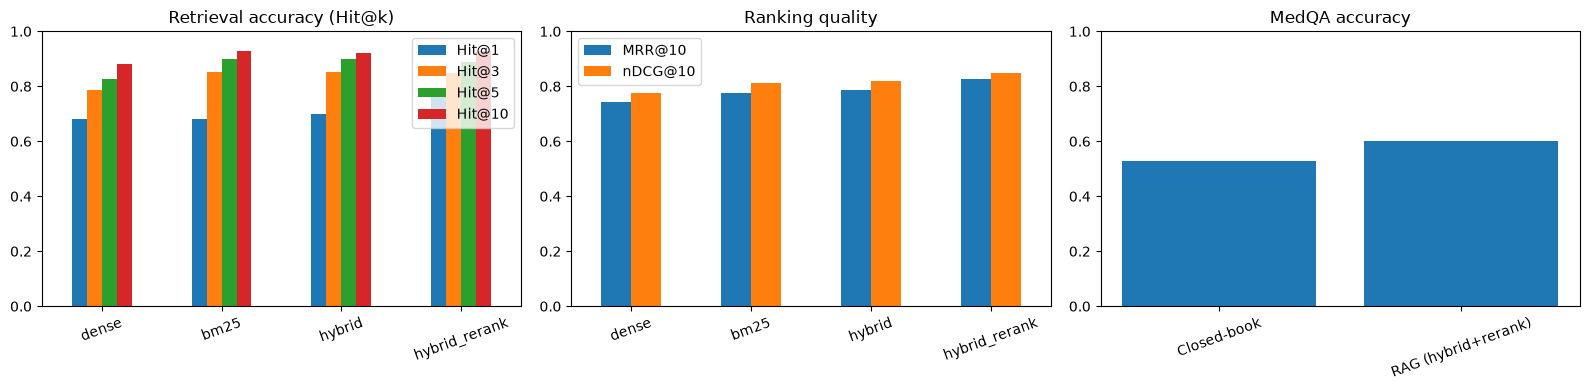

=== RETRIEVAL ===
               Hit@1  Precision@1  Recall@1  Hit@3  Precision@3  Recall@3  Hit@5  Precision@5  Recall@5  Hit@10  Precision@10  Recall@10  MRR@10  nDCG@10
dense           0.68         0.68      0.68  0.787        0.262     0.787  0.827        0.165     0.827   0.880         0.088      0.880   0.743    0.776
bm25            0.68         0.68      0.68  0.853        0.284     0.853  0.900        0.180     0.900   0.927         0.093      0.927   0.775    0.813
hybrid          0.70         0.70      0.70  0.853        0.284     0.853  0.900        0.180     0.900   0.920         0.092      0.920   0.785    0.818
hybrid_rerank   0.78         0.78      0.78  0.847        0.282     0.847  0.887        0.177     0.887   0.927         0.093      0.927   0.825    0.849

=== ANSWER QUALITY ===
Correctness        0.700
Token-F1           0.343
ROUGE-L            0.320
BLEU               0.140
SemanticSim        0.786
Faithfulness       0.950
AnswerRelevancy    0.925
Hallucination

In [ ]:
import matplotlib.pyplot as plt

report = {
    "settings": {"llm": LLM_MODEL, "embedder": EMBED_MODEL, "reranker": RERANK_MODEL,
                 "top_k": TOP_K_FINAL, "query_rewrite": USE_QUERY_REWRITE, "thinking": THINK,
                 "n_chunks": len(texts), "n_synthetic": len(synth), "n_answer_eval": len(gen_df), "n_medqa": len(medqa)},
    "retrieval": retrieval_df.to_dict(orient="index"),
    "answer_quality": answer_summary.to_dict(),
    "medqa": medqa_summary.to_dict(orient="records"),
    "latency": latency_df.to_dict(orient="index"),
}
json.dump(report, open(f"{RESULTS_DIR}/final_report.json", "w"), indent=2, default=float)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
retrieval_df[[f"Hit@{k}" for k in KS]].plot.bar(ax=ax[0], ylim=(0, 1)); ax[0].set_title("Retrieval accuracy (Hit@k)")
retrieval_df[["MRR@10", "nDCG@10"]].plot.bar(ax=ax[1], ylim=(0, 1)); ax[1].set_title("Ranking quality")
ax[2].bar(medqa_summary["system"], medqa_summary["accuracy"]); ax[2].set_ylim(0, 1); ax[2].set_title("MedQA accuracy")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/summary.png", dpi=150); plt.show()

print("=== RETRIEVAL ===");      print(retrieval_df.to_string())
print("\n=== ANSWER QUALITY ==="); print(answer_summary.to_string())
print("\n=== MEDQA ===");        print(medqa_summary.to_string(index=False))
print("\n=== LATENCY ===");      print(latency_df.to_string())

C:\Users\Vibhi Sharma\AppData\Local\Temp\ipykernel_15000\326971128.py:24: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype float64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  answer_summary[name] = f"{series.mean():.3f}  (95% CI {lo:.2f}-{hi:.2f})"


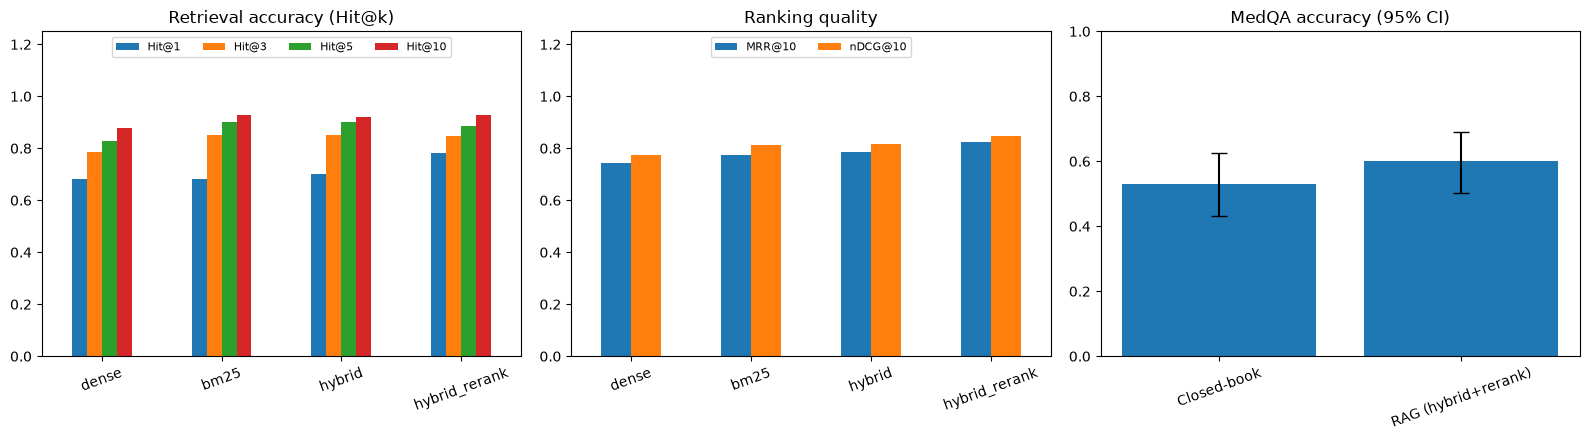

=== ANSWER QUALITY ===
Correctness (judge v1)            0.700  (95% CI 0.55-0.82)
Correctness (judge v2)            0.900  (95% CI 0.77-0.96)
Correctness (audited, lenient)    0.975  (95% CI 0.87-1.00)
Correctness (audited, strict)     0.950  (95% CI 0.83-0.99)
Token-F1                                              0.343
ROUGE-L                                                0.32
BLEU                                                   0.14
SemanticSim                                           0.786
Faithfulness                                           0.95
AnswerRelevancy                                       0.925
Hallucination                                          0.05


In [ ]:
import matplotlib.pyplot as plt

# ---- audit lists (same as before; redefined here so the cell is self-contained) ----
human_says_correct    = [1, 16, 17, 26]   # judge v2 said wrong, human accepts
judge_false_positive  = [19]              # judge v2 said right, human rejects
borderline            = [35]              # counted wrong only in the strict version

def audited(strict):
    s = gen_df["Correctness_v2"].copy()
    s.loc[human_says_correct] = 1
    s.loc[judge_false_positive] = 0
    if strict:
        s.loc[borderline] = 0
    return s

# ---- answer-quality summary: no ambiguous "Correctness" row any more ----
other_cols = ["Token-F1", "ROUGE-L", "BLEU", "SemanticSim", "Faithfulness", "AnswerRelevancy", "Hallucination"]
answer_summary = gen_df[other_cols].mean().round(3)
for name, series in [("Correctness (judge v1)", gen_df["Correctness"]),
                     ("Correctness (judge v2)", gen_df["Correctness_v2"]),
                     ("Correctness (audited, lenient)", audited(False)),
                     ("Correctness (audited, strict)", audited(True))]:
    lo, hi = wilson_ci(series.sum(), len(series))
    answer_summary[name] = f"{series.mean():.3f}  (95% CI {lo:.2f}-{hi:.2f})"
answer_summary = answer_summary.reindex(
    [c for c in answer_summary.index if c.startswith("Correctness")] + other_cols)

# ---- MedQA CIs for the chart ----
acc, err_lo, err_hi = [], [], []
for _, row in medqa_summary.iterrows():
    g = mcq_df[mcq_df.system == row["system"]]
    lo, hi = wilson_ci(g["correct"].sum(), len(g))
    acc.append(g["correct"].mean()); err_lo.append(acc[-1] - lo); err_hi.append(hi - acc[-1])

# ---- save the corrected report ----
report = {
    "settings": {"llm": LLM_MODEL, "embedder": EMBED_MODEL, "reranker": RERANK_MODEL,
                 "top_k": TOP_K_FINAL, "query_rewrite": USE_QUERY_REWRITE, "thinking": THINK,
                 "n_chunks": len(texts), "n_synthetic": len(synth),
                 "n_answer_eval": len(gen_df), "n_medqa": len(medqa)},
    "retrieval": retrieval_df.to_dict(orient="index"),
    "answer_quality": answer_summary.to_dict(),
    "audit_notes": {
        "judge_v2": "rubric rewritten after inspecting judge v1 errors (v1 marked correct answers wrong)",
        "rows_human_accepted": human_says_correct,
        "rows_human_rejected": judge_false_positive,
        "rows_borderline": borderline,
        "caveat": "questions and references are LLM-generated from the same corpus; audit by one reader who had seen the scores",
    },
    "medqa": medqa_summary.to_dict(orient="records"),
    "latency": latency_df.to_dict(orient="index"),
}
json.dump(report, open(f"{RESULTS_DIR}/final_report.json", "w"), indent=2, default=float)

# ---- charts (legends moved out of the way, MedQA error bars added) ----
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
retrieval_df[[f"Hit@{k}" for k in KS]].plot.bar(ax=ax[0], ylim=(0, 1.25))
ax[0].set_title("Retrieval accuracy (Hit@k)"); ax[0].legend(loc="upper center", ncol=4, fontsize=8)
retrieval_df[["MRR@10", "nDCG@10"]].plot.bar(ax=ax[1], ylim=(0, 1.25))
ax[1].set_title("Ranking quality"); ax[1].legend(loc="upper center", ncol=2, fontsize=8)
ax[2].bar(medqa_summary["system"], acc, yerr=[err_lo, err_hi], capsize=6)
ax[2].set_ylim(0, 1); ax[2].set_title("MedQA accuracy (95% CI)")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/summary.png", dpi=150); plt.show()

print("=== ANSWER QUALITY ==="); print(answer_summary.to_string())

## 14. If a number is lower than you want — what to change
Change one thing at a time, re-run, and report whatever you actually measure.

| Problem | Try |
|---|---|
| Hit@5 low | raise `N_CANDIDATES` to 40; swap `RERANK_MODEL` for `BAAI/bge-reranker-base` or `ncbi/MedCPT-Cross-Encoder`; swap `EMBED_MODEL` for `BAAI/bge-base-en-v1.5` (re-embeds, ~3x slower) |
| MedQA accuracy low | this is mostly limited by the **LLM size**. Try `ollama pull qwen3:8b` (or another larger model your RAM allows), set `THINK = True`, or raise `TOP_K_FINAL` to 8 (keep `num_ctx` large enough) |
| Hallucination high | keep the "ONLY the context" instruction, lower `TOP_K_FINAL` noise by reranking harder, use a bigger LLM |
| Too slow | lower `N_SYNTH`, `N_GEN_EVAL`, `N_MEDQA`; set `USE_QUERY_REWRITE = False` |

## 15. Ask your own question

In [ ]:
question = "What is the blood supply of the scaphoid bone and why does it matter after a fracture?"
out = rag_answer(question)
print(out["answer"])
print("\nSources:")
for n, i in enumerate(out["idxs"], 1):
    print(f"[{n}] {titles[i]} ({chunk_ids[i]})")

The scaphoid bone has a blood supply that primarily comes from a branch of the radial artery, which enters the distal portion of the bone and supplies the proximal portion [2]. In approximately 10% of individuals, this is the sole blood supply to the proximal scaphoid [2]. When a fracture occurs across the waist of the scaphoid, the proximal portion loses its blood supply and may develop avascular necrosis, a complication that can lead to nonunion and long-term joint damage [5]. This matters because the interruption of blood flow significantly increases the risk of avascular necrosis after a fracture, especially in cases where the fracture disrupts the retrograde blood supply [1].

Sources:
[1] Surgery_Schwartz (medrag_Surgery_Schwartz_12473)
[2] Anatomy_Gray (medrag_Anatomy_Gray_2006)
[3] Anatomy_Gray (medrag_Anatomy_Gray_1641)
[4] Pathology_Robbins (medrag_Pathology_Robbins_4776)
[5] First_Aid_Step1 (medrag_First_Aid_Step1_493)


In [ ]:
from collections import Counter

medqa_train = load_dataset("GBaker/MedQA-USMLE-4-options", split="train")
rng = random.Random(1)
dev = [medqa_train[i] for i in rng.sample(range(len(medqa_train)), 60)]   # never overlaps the test set

def retrieve_for_mcq(item, per_option):
    q = rewrite_query(item["question"]) if USE_QUERY_REWRITE else item["question"]
    lists = [retrieve(q, "hybrid", 30)]
    if per_option:                                   # also search "question + each answer option"
        for opt in item["options"].values():
            lists.append(retrieve(f"{q} {opt}", "hybrid", 30))
    fused = rrf_fuse(lists)[:N_CANDIDATES]
    scores = reranker.predict([(q, texts[i]) for i in fused], batch_size=16, show_progress_bar=False)
    return [fused[i] for i in np.argsort(-scores)][:TOP_K_FINAL]

def ask_mcq2(item, use_rag=True, per_option=False, votes=1):
    options = "\n".join(f"{k}. {v}" for k, v in item["options"].items())
    ctx = ""
    if use_rag:
        ctx = "Context from medical textbooks:\n" + build_context(retrieve_for_mcq(item, per_option)) + "\n\n"
    prompt = f"""{ctx}You are an expert physician answering a USMLE question. Think about the most likely diagnosis or mechanism, then pick the best option. Use the context only if it is relevant.

Question: {item['question']}

Options:
{options}

Reply with only the letter (A, B, C or D) of the best answer."""
    preds = []
    for _ in range(votes):
        reply = llm(prompt, max_tokens=8, temperature=0.0 if votes == 1 else 0.6)
        m = re.search(r"\b([A-D])\b", reply)
        preds.append(m.group(1) if m else None)
    return Counter(p for p in preds if p).most_common(1)[0][0] if any(preds) else None

def run_experiment(name, items=dev, model=None, think=None, top_k=None, **kwargs):
    global LLM_MODEL, THINK, TOP_K_FINAL
    old = (LLM_MODEL, THINK, TOP_K_FINAL)
    LLM_MODEL = model or LLM_MODEL; THINK = old[1] if think is None else think; TOP_K_FINAL = top_k or TOP_K_FINAL
    try:
        correct = sum(int(ask_mcq2(it, **kwargs) == it["answer_idx"]) for it in tqdm(items, desc=name))
    finally:
        LLM_MODEL, THINK, TOP_K_FINAL = old
    lo, hi = wilson_ci(correct, len(items))
    print(f"{name}: {correct/len(items):.3f}  (95% CI {lo:.2f}-{hi:.2f}, n={len(items)})")
    return correct / len(items)

results = {}
results["baseline"] = run_experiment("baseline (current setup)")

NameError: name 'load_dataset' is not defined